In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load the dataset
df = pd.read_csv("Ecommerce_Purchase_Prediction_DataSet.csv")
df.head()

,Customer_ID,Age,Gender,Device_Type,Traffic_Source,Membership_Type,Payment_Method,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
0,CUST00001,37.0,Female,Mobile,Referral,Regular,Credit Card,6.78,5.0,8,0,4933.27,14.05,2,3.09,0.273,4.07,1,1
1,CUST00002,24.0,Male,Mobile,Organic,Premium,Debit Card,12.79,9.0,5,1,3042.60,7.28,2,48.27,0.045,4.19,0,1
2,CUST00003,42.0,Female,Mobile,Referral,Regular,Wallet,11.72,9.0,5,1,NaN,9.77,4,3.82,0.796,3.37,2,0
3,CUST00004,43.0,Male,Tablet,Referral,Premium,UPI,10.67,7.0,6,3,2776.48,6.78,0,9.24,0.426,5.00,1,1
4,CUST00005,18.0,Male,Desktop,Social Media,Regular,Debit Card,12.06,4.0,3,4,3683.66,16.37,4,4.46,0.347,2.16,0,1


In [3]:
df.shape

(10000, 19)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    9762 non-null   float64
 2   Gender                 9796 non-null   str    
 3   Device_Type            9855 non-null   str    
 4   Traffic_Source         9760 non-null   str    
 5   Membership_Type        9791 non-null   str    
 6   Payment_Method         9787 non-null   str    
 7   Session_Duration_Min   9776 non-null   float64
 8   Pages_Viewed           10000 non-null  float64
 9   Products_Viewed        10000 non-null  int64  
 10  Cart_Items             10000 non-null  int64  
 11  Cart_Value_INR         9675 non-null   float64
 12  Discount_Percent       9789 non-null   float64
 13  Previous_Orders        10000 non-null  int64  
 14  Days_Since_Last_Visit  9820 non-null   float64
 15  Email_Open_Rat

In [6]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'Device_Type', 'Traffic_Source',
       'Membership_Type', 'Payment_Method', 'Session_Duration_Min',
       'Pages_Viewed', 'Products_Viewed', 'Cart_Items', 'Cart_Value_INR',
       'Discount_Percent', 'Previous_Orders', 'Days_Since_Last_Visit',
       'Email_Open_Rate', 'Customer_Rating', 'Returns_Last_Year', 'Purchase'],
      dtype='str')

In [7]:
df.describe()

,Age,Session_Duration_Min,Pages_Viewed,Products_Viewed,Cart_Items,Cart_Value_INR,Discount_Percent,Previous_Orders,Days_Since_Last_Visit,Email_Open_Rate,Customer_Rating,Returns_Last_Year,Purchase
count,9762.000000,9776.000000,10000.000000,10000.000000,10000.000000,9675.000000,9789.000000,10000.000000,9820.000000,10000.000000,9675.000000,10000.000000,10000.000000
mean,34.127228,13.117865,7.274137,3.991100,1.523000,1912.614298,12.178725,2.997800,13.314532,0.500227,3.778779,0.601300,0.648000
std,9.546429,12.737399,6.055331,1.999555,1.228015,3831.569883,8.143978,1.725947,26.690252,0.290871,0.754031,0.775241,0.477618
min,18.000000,1.000000,1.000000,0.000000,0.000000,14.930000,0.140000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,27.000000,6.780000,5.000000,3.000000,1.000000,819.930000,6.450000,2.000000,3.460000,0.246000,3.270000,0.000000,0.000000
50%,34.000000,10.835000,7.000000,4.000000,1.000000,1433.270000,10.820000,3.000000,8.470000,0.502000,3.800000,0.000000,1.000000
75%,40.000000,16.642500,9.000000,5.000000,2.000000,2279.965000,16.220000,4.000000,16.745000,0.751250,4.340000,1.000000,1.000000
max,74.000000,227.756046,148.075292,12.000000,7.000000,88342.757367,99.149690,15.000000,671.772129,1.000000,5.000000,6.000000,1.000000


In [8]:
# missing values

print(df.isnull().sum())

Customer_ID                0
Age                      238
Gender                   204
Device_Type              145
Traffic_Source           240
Membership_Type          209
Payment_Method           213
Session_Duration_Min     224
Pages_Viewed               0
Products_Viewed            0
Cart_Items                 0
Cart_Value_INR           325
Discount_Percent         211
Previous_Orders            0
Days_Since_Last_Visit    180
Email_Open_Rate            0
Customer_Rating          325
Returns_Last_Year          0
Purchase                   0
dtype: int64


In [9]:
# total missing values
print(df.isnull().sum().sum())

2514


In [10]:
#check missing values in %
print(df.isnull().sum()/ len(df)*100)

Customer_ID              0.00
Age                      2.38
Gender                   2.04
Device_Type              1.45
Traffic_Source           2.40
Membership_Type          2.09
Payment_Method           2.13
Session_Duration_Min     2.24
Pages_Viewed             0.00
Products_Viewed          0.00
Cart_Items               0.00
Cart_Value_INR           3.25
Discount_Percent         2.11
Previous_Orders          0.00
Days_Since_Last_Visit    1.80
Email_Open_Rate          0.00
Customer_Rating          3.25
Returns_Last_Year        0.00
Purchase                 0.00
dtype: float64


In [23]:
#Numerical columns
num_cols=df.select_dtypes(include=['int64','float64']).columns
print(num_cols)

#Categ columns
cat_col=df.select_dtypes(include=['str']).columns
print(cat_col)

Index(['Age', 'Session_Duration_Min', 'Pages_Viewed', 'Products_Viewed',
       'Cart_Items', 'Cart_Value_INR', 'Discount_Percent', 'Previous_Orders',
       'Days_Since_Last_Visit', 'Email_Open_Rate', 'Customer_Rating',
       'Returns_Last_Year', 'Purchase'],
      dtype='str')
Index(['Customer_ID', 'Gender', 'Device_Type', 'Traffic_Source',
       'Membership_Type', 'Payment_Method'],
      dtype='str')


In [24]:
#check missing values treatment

#num cols---median
#cat cols---mode

In [25]:
# use the median imputation to replace missing numerical values

for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [6]:
# Handle missing values in categorical columns
for col in cat_col:
    df[col]=df[col].fillna(df[col].mode()[0])

In [34]:
df.isnull().sum()

Customer_ID              0
Age                      0
Gender                   0
Device_Type              0
Traffic_Source           0
Membership_Type          0
Payment_Method           0
Session_Duration_Min     0
Pages_Viewed             0
Products_Viewed          0
Cart_Items               0
Cart_Value_INR           0
Discount_Percent         0
Previous_Orders          0
Days_Since_Last_Visit    0
Email_Open_Rate          0
Customer_Rating          0
Returns_Last_Year        0
Purchase                 0
dtype: int64

In [16]:
print(df.duplicated().sum())

0


In [17]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

Age : 58
Session_Duration_Min : 351
Pages_Viewed : 45
Products_Viewed : 216
Cart_Items : 694
Cart_Value_INR : 374
Discount_Percent : 193
Previous_Orders : 119
Days_Since_Last_Visit : 529
Email_Open_Rate : 0
Customer_Rating : 37
Returns_Last_Year : 228
Purchase : 0


In [8]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [33]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

Age : 0
Session_Duration_Min : 0
Pages_Viewed : 0
Products_Viewed : 0
Cart_Items : 0
Cart_Value_INR : 0
Discount_Percent : 0
Previous_Orders : 0
Days_Since_Last_Visit : 0
Email_Open_Rate : 0
Customer_Rating : 0
Returns_Last_Year : 0
Purchase : 0


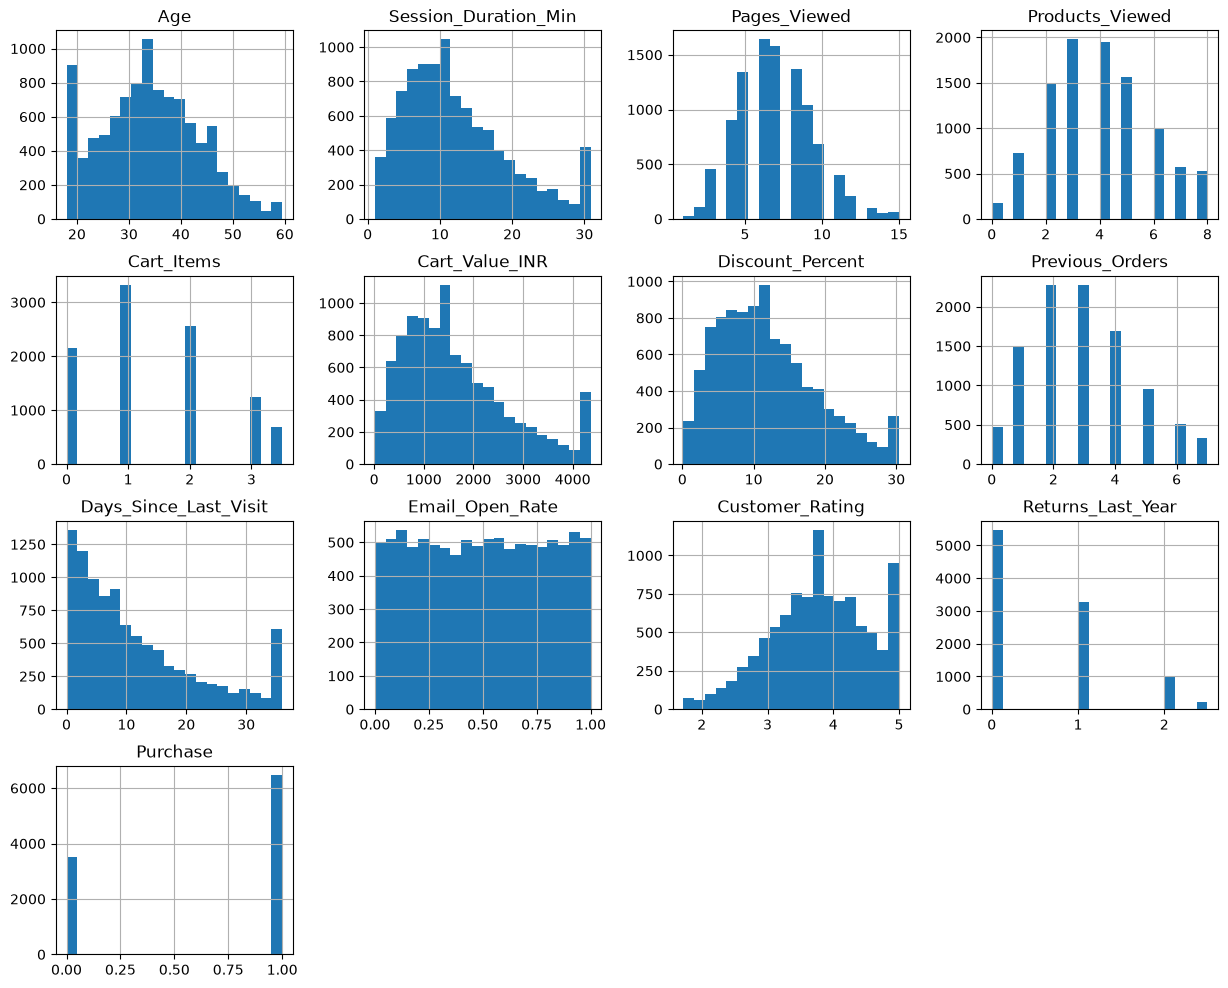

In [10]:
# Distribution of numerical columns
df[num_cols].hist(figsize=(15,12),bins=20)
plt.show()

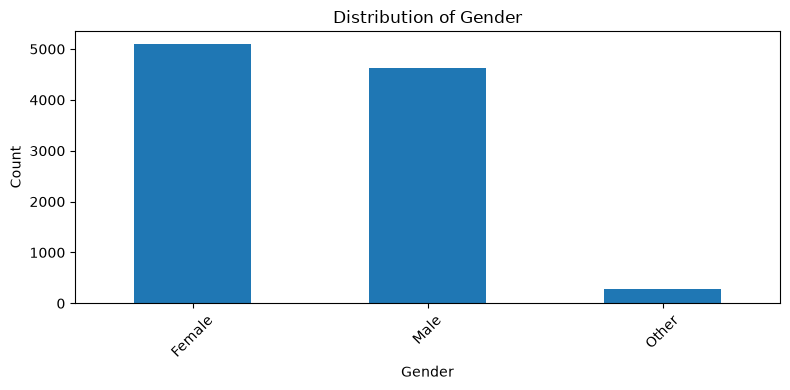

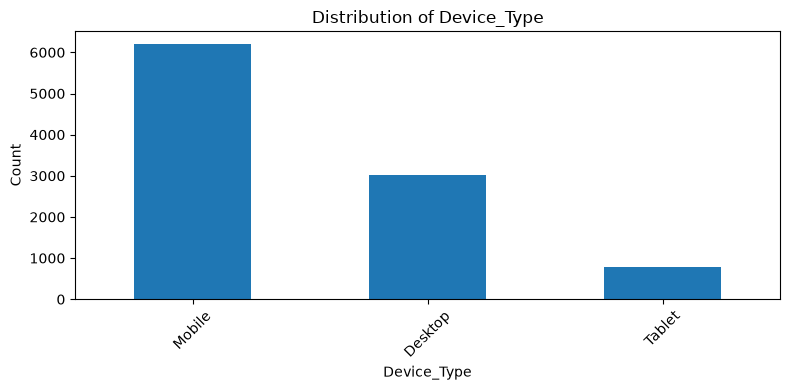

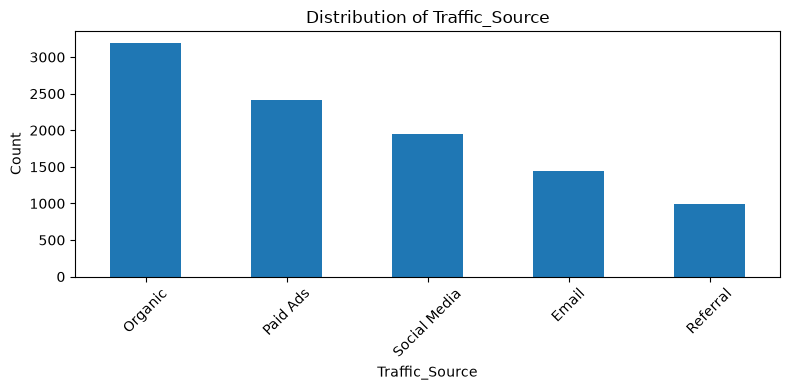

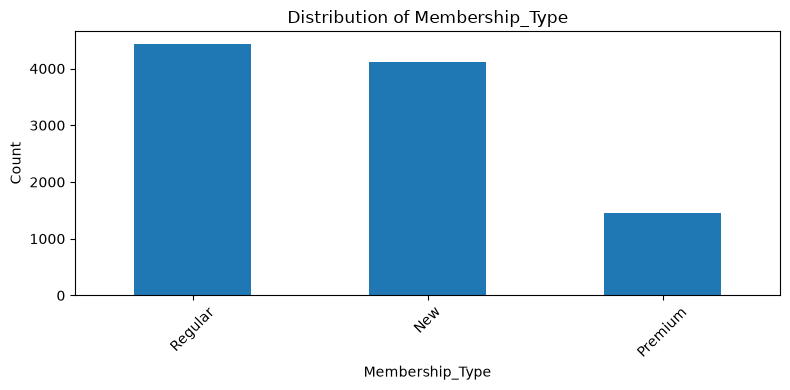

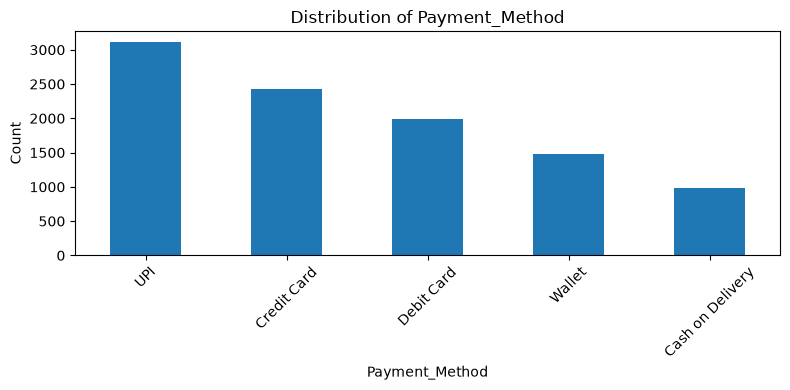

In [32]:
# Distribution of categorical columns

for col in cat_col[1:]:
    plt.figure(figsize=(8, 4))

    df[col].value_counts().plot(kind='bar')

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()